# TP Jour 2 — Modèle d'Exécution Spark, Jointures Multi-Datasets & Couche Silver (Delta Lake)

### Objectifs de la séance
1. Observer la **Lazy Evaluation** et distinguer transformations **Narrow** vs **Wide (Shuffle)** sur **Spark Web UI** (`http://localhost:4040`).
2. Profiler la qualité de vos tables **Bronze** (issues d'un ou **plusieurs datasets Kaggle**), nettoyer les anomalies, typer fortement les colonnes et harmoniser les **clés de jointure inter-sources**.
3. Mettre en œuvre une **jointure distribuée multi-datasets maîtrisée** (`BroadcastHashJoin` via `F.broadcast` pour un référentiel/dataset compact, ou `SortMergeJoin` entre deux grandes sources) **en contrôlant la cardinalité (absence d'explosion N-à-M)**.
4. Sauvegarder votre table analytique enrichie dans **`/lakehouse/silver/`** et expérimenter les garanties **ACID de Delta Lake** (`_delta_log`, **Schema Enforcement**, **`MERGE INTO`**, **Time Travel**).
5. Mener une **Analyse Exploratoire des Données (EDA)** et produire des **visualisations 1D, 2D et multidimensionnelles (ACP / PCA)** sur la couche Silver.

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from delta.tables import DeltaTable

spark = (
    SparkSession.builder
    .appName("J2_Spark_Delta_Silver")
    .getOrCreate()
)

print("Session Spark active — Spark UI : http://localhost:4040")

Session Spark active — Spark UI : http://localhost:4040


## 1. Chargement de vos tables Bronze (Multi-Datasets / Multi-Tables) & Diagnostic Qualité

### Exercice 1.1 — Charger toutes vos tables Bronze et profiler valeurs manquantes / doublons
1. Chargez dans `bronze_dfs` votre table de faits principale ainsi que la (ou les) table(s) secondaire(s) à joindre depuis `/lakehouse/bronze/<nom_table>`.
2. Comptez le nombre de valeurs `NULL` sur vos colonnes clés (en particulier les **clés de jointure**) ainsi que les doublons éventuels.

In [3]:
# --- 1. Découverte automatique des tables Delta Bronze sur HDFS (code fourni) ---
fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
PathHDFS = spark._jvm.org.apache.hadoop.fs.Path

bronze_dfs = {}
for s in sorted(fs.listStatus(PathHDFS("/lakehouse/bronze")), key=lambda x: x.getPath().getName()):
    name = s.getPath().getName()
    if s.isDirectory() and fs.exists(PathHDFS(s.getPath(), "_delta_log")):  # garde uniquement les tables Delta (exclut raw/)
        df = spark.read.format("delta").load(f"/lakehouse/bronze/{name}")
        bronze_dfs[name] = df
        print(f"[{name:<42}] -> {df.count():>9,} lignes | {df.columns[:5]}")

# --- 2. Diagnostic des NULL sur les dimensions (petites tables, complètes) ---
for name in ["airlines", "airports"]:
    df = bronze_dfs[name]
    cols = [c for c in df.columns if not c.startswith("_")]
    print(f"\n=== Valeurs nulles : {name} ===")
    df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in cols]).show(truncate=False)

# --- 3. Table principale : échantillon reproductible de 5 % des vols, mis en cache ---
SAMPLE_FRACTION = 0.05
df_bronze = bronze_dfs["flights"].sample(fraction=SAMPLE_FRACTION, seed=42).cache()
print(f"\nÉchantillon flights ({SAMPLE_FRACTION:.0%}) : {df_bronze.count():,} lignes")  # 1re action -> remplit le cache

# --- 4. Diagnostic des NULL sur l'échantillon (1 seul passage pour toutes les colonnes) ---
cols = [c for c in df_bronze.columns if not c.startswith("_")]
null_report = df_bronze.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in cols])
assert null_report is not None, "TODO : Calculez le diagnostic de valeurs nulles `null_report`."
print("=== Valeurs nulles : flights (échantillon) ===")
null_report.show(truncate=False)

# --- 5. Doublons exacts (dropDuplicates = transformation wide -> shuffle) ---
n_dup = df_bronze.count() - df_bronze.dropDuplicates(cols).count()
print(f"Doublons exacts dans l'échantillon : {n_dup:,}")

26/11/19 08:53:13 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


[airlines                                  ] ->        14 lignes | ['iata_code', 'airline', '_ingested_at', '_source_dataset', '_source_file']


[airports                                  ] ->       322 lignes | ['iata_code', 'airport', 'city', 'state', 'country']


[flights                                   ] -> 5,819,079 lignes | ['year', 'month', 'day', 'day_of_week', 'airline']

=== Valeurs nulles : airlines ===
+---------+-------+
|iata_code|airline|
+---------+-------+
|0        |0      |
+---------+-------+


=== Valeurs nulles : airports ===
+---------+-------+----+-----+-------+--------+---------+
|iata_code|airport|city|state|country|latitude|longitude|
+---------+-------+----+-----+-------+--------+---------+
|0        |0      |0   |0    |0      |3       |3        |
+---------+-------+----+-----+-------+--------+---------+




Échantillon flights (5%) : 290,944 lignes
=== Valeurs nulles : flights (échantillon) ===
+----+-----+---+-----------+-------+-------------+-----------+--------------+-------------------+-------------------+--------------+---------------+--------+----------+--------------+------------+--------+--------+---------+-------+-----------------+------------+-------------+--------+---------+-------------------+----------------+--------------+-------------+-------------------+-------------+
|year|month|day|day_of_week|airline|flight_number|tail_number|origin_airport|destination_airport|scheduled_departure|departure_time|departure_delay|taxi_out|wheels_off|scheduled_time|elapsed_time|air_time|distance|wheels_on|taxi_in|scheduled_arrival|arrival_time|arrival_delay|diverted|cancelled|cancellation_reason|air_system_delay|security_delay|airline_delay|late_aircraft_delay|weather_delay|
+----+-----+---+-----------+-------+-------------+-----------+--------------+-------------------+-------------------

Doublons exacts dans l'échantillon : 0


## 2. Harmonisation Inter-Datasets, Nettoyage & Jointure Distribuée (`BroadcastHashJoin` / `SortMergeJoin`)

### Bonnes pratiques de jointure entre plusieurs datasets hétérogènes :
1. **Harmonisation des clés de jointure (*Key Alignment*)** : deux datasets Kaggle d'auteurs différents n'ont presque jamais exactement le même format de clé :
   - *Axe temporel* : ramenez les horodatages à la même granularité et au même fuseau (`F.to_date(...)`, `F.date_trunc("hour", ...)` ou format `yyyy-MM`).
   - *Axe géographique / catégoriel* : normalisez la casse, les espaces et les codes (`F.upper(F.trim(col))`, code ISO pays/région, code postal ou grille `F.round(lat, 2)`).
2. **Prévention des explosions N-à-M** : avant un `LEFT JOIN` de la table principale (`N` lignes) vers un second dataset, assurez-vous que la clé de jointure est **unique côté table secondaire** via une pré-agrégation métier (`groupBy(join_keys).agg(...)`) ou `dropDuplicates(join_keys)` ! Vérifiez systématiquement que le nombre de lignes après `LEFT JOIN` n'explose pas.
3. **Choix de la stratégie physique Spark** :
   - **Table secondaire compacte (< quelques dizaines de Mo)** : forcez **`F.broadcast(df_sec)`** pour obtenir un `BroadcastHashJoin` sans *Shuffle* de la grande table.
   - **Deux grands datasets volumineux** : laissez Spark exécuter un `SortMergeJoin` distribué (optimisé dynamiquement par *Adaptive Query Execution*).

### Exercice 2.1 — Nettoyer, harmoniser vos clés, joindre vos sources et écrire `/lakehouse/silver/<table_silver>`
1. Nettoyez vos tables (`dropDuplicates`, filtrage d'anomalies, typage fort `F.to_timestamp` / `F.to_date` / numériques) et harmonisez la clé de jointure commune.
2. Créez au moins **2 nouvelles colonnes métier dérivées** (dont idéalement un indicateur combinant vos deux sources !) utiles pour les Jours 3 & 4.
3. Réalisez la jointure (avec `F.broadcast(...)` sur une table de dimension/dataset secondaire compact), contrôlez le **taux de rapprochement (*match rate*)** ainsi que l'absence de duplication N-M, et affichez `.explain("simple")`.
4. Écrivez la table enrichie au format **Delta** dans **`/lakehouse/silver/<votre_table>`**.

#### Étape A — Profilage complet, nettoyage & typage de la table de faits `flights`
- Profilage sur le **dataset complet** pour détecter les anomalies rares que l'échantillon pourrait manquer.
- Nettoyage / typage sur l'**échantillon** (`df_bronze`), rapport qualité par règle, puis barrières `assert`.
- Choix : les vols aux codes aéroport non IATA (octobre 2015) sont **conservés** et signalés par `airport_code_valid`.

In [12]:
IATA_REGEX = "^[A-Z]{3}$"  # un code aéroport IATA = exactement 3 lettres majuscules

# =====================================================================
# 1. PROFILAGE SUR LE DATASET COMPLET (5,8 M lignes, 1 seul passage, sans cache)
#    -> détecter les anomalies rares que l'échantillon de 5 % aurait pu manquer
# =====================================================================
df_full = bronze_dfs["flights"]
key_cols = ["year", "month", "day", "airline", "flight_number", "origin_airport", "destination_airport", "scheduled_departure", "distance"]
range_cols = ["scheduled_departure", "scheduled_arrival", "distance", "scheduled_time", "departure_delay", "arrival_delay"]

full_profile = df_full.agg(
    F.count("*").alias("n_rows"),
    *[F.count(F.when(F.col(c).isNull(), c)).alias(f"null_{c}") for c in key_cols],
    *[F.min(c).alias(f"min_{c}") for c in range_cols],
    *[F.max(c).alias(f"max_{c}") for c in range_cols],
    F.sum((~F.col("origin_airport").cast("string").rlike(IATA_REGEX)).cast("int")).alias("n_origin_not_iata"),
    F.sum((~F.col("destination_airport").cast("string").rlike(IATA_REGEX)).cast("int")).alias("n_dest_not_iata"),
    F.sum((F.col("scheduled_departure") >= 2400).cast("int")).alias("n_sched_dep_ge_2400"),
    F.sum((F.col("distance") <= 0).cast("int")).alias("n_distance_le_0"),
).collect()[0].asDict()  # 1 seule ligne -> on la rapatrie en dictionnaire Python

print("=== Profil du dataset COMPLET (flights) ===")
for k, v in full_profile.items():
    print(f"  {k:<28} {v:>12,}" if v is not None else f"  {k:<28} {'NULL':>12}")

# =====================================================================
# 2. NETTOYAGE & TYPAGE (sur l'échantillon df_bronze) — transformations narrow uniquement
# =====================================================================
df_clean = (
    df_bronze
    # Date typée
    .withColumn("flight_date", F.make_date("year", "month", "day"))
    # Heure prévue HHMM : 5 -> "0005", puis timestamp. try_to_timestamp -> NULL si invalide (ex. 2400) au lieu de planter (mode ANSI)
    .withColumn("dep_hhmm", F.lpad(F.col("scheduled_departure").cast("string"), 4, "0"))
    .withColumn("scheduled_dep_ts", F.try_to_timestamp(
        F.concat_ws(" ", F.col("flight_date").cast("string"), F.col("dep_hhmm")),
        F.lit("yyyy-MM-dd HHmm")))
    .drop("dep_hhmm")
    # Booléens lisibles à la place des 0/1
    .withColumn("is_cancelled", F.col("cancelled") == 1)
    .withColumn("is_diverted", F.col("diverted") == 1)
    .drop("cancelled", "diverted")
    # Harmonisation des clés de jointure
    .withColumn("airline", F.upper(F.trim(F.col("airline"))))
    .withColumn("origin_airport", F.upper(F.trim(F.col("origin_airport").cast("string"))))
    .withColumn("destination_airport", F.upper(F.trim(F.col("destination_airport").cast("string"))))
    # Indicateur de validité du format des codes aéroport (option ii : on garde les lignes, on signale)
    .withColumn("airport_code_valid",
        F.col("origin_airport").rlike(IATA_REGEX) & F.col("destination_airport").rlike(IATA_REGEX))
)

# =====================================================================
# 3. RAPPORT QUALITÉ : combien de lignes chaque règle signale / va rejeter
# =====================================================================
quality = df_clean.agg(
    F.count("*").alias("n_total"),
    F.sum(F.col("scheduled_dep_ts").isNull().cast("int")).alias("n_invalid_ts"),
    F.sum((F.col("distance") <= 0).cast("int")).alias("n_distance_le_0"),
    F.sum((~F.col("airport_code_valid")).cast("int")).alias("n_airport_code_invalid"),
).collect()[0].asDict()

print("\n=== Rapport qualité (échantillon) ===")
for k, v in quality.items():
    print(f"  {k:<26} {v:>9,}  ({v / quality['n_total']:6.2%})")

# Rejet des lignes inexploitables (les codes aéroport invalides sont CONSERVÉS et signalés)
df_clean = df_clean.filter(F.col("scheduled_dep_ts").isNotNull() & (F.col("distance") > 0))

print("\nCodes aéroport invalides par mois :")
(df_clean.groupBy("month")
    .agg(F.count("*").alias("n_flights"),
         F.sum((~F.col("airport_code_valid")).cast("int")).alias("n_invalid_codes"))
    .orderBy("month")
    .show(12))

# =====================================================================
# 4. UNICITÉ DE LA CLÉ MÉTIER D'UN VOL (prépare le MERGE) — dropDuplicates = wide (shuffle)
# =====================================================================
flight_key = ["flight_date", "airline", "flight_number", "origin_airport", "scheduled_departure"]
n_clean = df_clean.count()
n_key_dup = n_clean - df_clean.dropDuplicates(flight_key).count()
print(f"Lignes après nettoyage : {n_clean:,} | doublons sur la clé métier {flight_key} : {n_key_dup:,}")

# =====================================================================
# 5. BARRIÈRES QUALITÉ (quality gates) : le notebook s'arrête si une anomalie imprévue apparaît
# =====================================================================
assert quality["n_invalid_ts"] / quality["n_total"] < 0.001, "Trop de timestamps invalides : nouvelle anomalie à investiguer !"
assert quality["n_distance_le_0"] / quality["n_total"] < 0.001, "Trop de distances <= 0 : nouvelle anomalie à investiguer !"
assert n_key_dup == 0, "Clé métier non unique : impossible de l'utiliser pour le MERGE !"
print("Barrières qualité OK")

=== Profil du dataset COMPLET (flights) ===
  n_rows                          5,819,079
  null_year                               0
  null_month                              0
  null_day                                0
  null_airline                            0
  null_flight_number                      0
  null_origin_airport                     0
  null_destination_airport                0
  null_scheduled_departure                0
  null_distance                           0
  min_scheduled_departure                 1
  min_scheduled_arrival                   1
  min_distance                           21
  min_scheduled_time                     18
  min_departure_delay                   -82
  min_arrival_delay                     -87
  max_scheduled_departure             2,359
  max_scheduled_arrival               2,400
  max_distance                        4,983
  max_scheduled_time                    718
  max_departure_delay                 1,988
  max_arrival_delay             


=== Rapport qualité (échantillon) ===
  n_total                      291,023  (100.00%)
  n_invalid_ts                       0  ( 0.00%)
  n_distance_le_0                    0  ( 0.00%)
  n_airport_code_invalid        24,381  ( 8.38%)

Codes aéroport invalides par mois :
+-----+---------+---------------+
|month|n_flights|n_invalid_codes|
+-----+---------+---------------+
|    1|    23442|              0|
|    2|    21720|              0|
|    3|    25207|              0|
|    4|    24272|              0|
|    5|    24893|              0|
|    6|    25162|              0|
|    7|    25954|              0|
|    8|    25554|              0|
|    9|    23148|              0|
|   10|    24381|          24381|
|   11|    23449|              0|
|   12|    23841|              0|
+-----+---------+---------------+



Lignes après nettoyage : 291,023 | doublons sur la clé métier ['flight_date', 'airline', 'flight_number', 'origin_airport', 'scheduled_departure'] : 0
Barrières qualité OK


#### Étape B — Colonnes métier dérivées sur la table de faits `flights`
- `dep_hour` : heure de départ prévue (0-23)
- `is_delayed_15` : retard à l'arrivée >= 15 min (norme officielle US) — NULL si vol non arrivé
- `delay_category` : cancelled / diverted / early / on_time / delayed / heavily_delayed
- `main_delay_cause` : cause de retard dominante (en minutes) parmi les 5 causes renseignées
- `route` : `ORIGIN-DEST`

In [13]:
# =====================================================================
# 1. CAUSE PRINCIPALE DU RETARD : la cause qui pèse le plus de minutes (ligne par ligne)
# =====================================================================
cause_cols = {
    "air_system_delay": "air_system",
    "security_delay": "security",
    "airline_delay": "airline",
    "late_aircraft_delay": "late_aircraft",
    "weather_delay": "weather",
}
max_cause = F.greatest(*[F.col(c) for c in cause_cols])  # max ligne par ligne (ignore les NULL)

# Construction d'une chaîne F.when(...).when(...) : du Python qui construit une expression Spark (rien n'est calculé ici)
main_cause_expr = None
for col_name, label in cause_cols.items():
    cond = F.col(col_name) == max_cause
    main_cause_expr = F.when(cond, label) if main_cause_expr is None else main_cause_expr.when(cond, label)

# =====================================================================
# 2. COLONNES MÉTIER (calculables sans l'autre source) — transformations narrow
# =====================================================================
df_features = (
    df_clean
    .withColumn("dep_hour", F.hour("scheduled_dep_ts"))
    .withColumn("is_delayed_15", F.col("arrival_delay") >= 15)  # NULL si annulé/dérouté (non arrivé)
    .withColumn("delay_category",
        F.when(F.col("is_cancelled"), "cancelled")          # en premier : arrival_delay est NULL pour ces vols
         .when(F.col("is_diverted"), "diverted")
         .when(F.col("arrival_delay") < 0, "early")
         .when(F.col("arrival_delay") < 15, "on_time")
         .when(F.col("arrival_delay") < 60, "delayed")
         .otherwise("heavily_delayed"))
    .withColumn("main_delay_cause", main_cause_expr)       # NULL si aucune cause renseignée
    .withColumn("route", F.concat_ws("-", "origin_airport", "destination_airport"))
)

# =====================================================================
# 3. CONTRÔLES : répartitions
# =====================================================================
print("Répartition des catégories de retard :")
df_features.groupBy("delay_category").count().orderBy(F.desc("count")).show()

print("Répartition des causes principales (vols avec retard >= 15 min) :")
df_features.filter(F.col("is_delayed_15")).groupBy("main_delay_cause").count().orderBy(F.desc("count")).show()

df_features.select("flight_date", "dep_hour", "route", "arrival_delay", "is_delayed_15", "delay_category", "main_delay_cause").show(8)

# =====================================================================
# 4. BARRIÈRES QUALITÉ
# =====================================================================
checks = df_features.agg(
    F.count("*").alias("n_total"),
    F.sum(F.col("delay_category").isNull().cast("int")).alias("n_category_null"),
    F.sum((F.col("is_cancelled") & (F.col("delay_category") != "cancelled")).cast("int")).alias("n_cancelled_misclassified"),
    F.sum(F.col("is_delayed_15").cast("int")).alias("n_delayed_15"),
    F.sum((F.col("is_delayed_15") & F.col("main_delay_cause").isNull()).cast("int")).alias("n_delayed_15_without_cause"),
).collect()[0].asDict()
print(checks)

assert checks["n_category_null"] == 0, "Des vols n'ont pas de delay_category !"
assert checks["n_cancelled_misclassified"] == 0, "Des vols annulés sont mal classés !"
assert checks["n_delayed_15_without_cause"] / checks["n_delayed_15"] < 0.01, "Trop de vols retardés >= 15 min sans cause renseignée !"
print("Barrières qualité étape B OK")

Répartition des catégories de retard :
+---------------+------+
| delay_category| count|
+---------------+------+
|          early|175199|
|        on_time| 57162|
|        delayed| 37012|
|heavily_delayed| 16357|
|      cancelled|  4561|
|       diverted|   732|
+---------------+------+

Répartition des causes principales (vols avec retard >= 15 min) :
+----------------+-----+
|main_delay_cause|count|
+----------------+-----+
|   late_aircraft|20699|
|         airline|15560|
|      air_system|15175|
|         weather| 1842|
|        security|   93|
+----------------+-----+

+-----------+--------+-------+-------------+-------------+--------------+----------------+
|flight_date|dep_hour|  route|arrival_delay|is_delayed_15|delay_category|main_delay_cause|
+-----------+--------+-------+-------------+-------------+--------------+----------------+
| 2015-01-01|       0|LAS-MCI|            6|        false|       on_time|            NULL|
| 2015-01-01|       5|BNA-ATL|            5|        fa

#### Étape C — Préparation des dimensions `airlines` et `airports`
- Clés harmonisées comme côté faits (`upper(trim(...))`), colonnes utiles uniquement, renommage sans conflit, types forcés.
- Barrière d'unicité des clés **avant** dédoublonnage (prévention de l'explosion N-M).
- *Role-playing dimension* : `airports` décliné en `dim_origin` (`origin_*`) et `dim_dest` (`dest_*`).
- Contrôle préalable (`left_anti`) des codes présents dans les vols mais absents des référentiels.

In [14]:
# =====================================================================
# 1. NETTOYAGE DES DIMENSIONS : clés harmonisées, colonnes utiles, noms sans conflit, types forcés
# =====================================================================
airlines_clean = bronze_dfs["airlines"].select(
    F.upper(F.trim("iata_code")).alias("airline_code"),   # même harmonisation que flights.airline
    F.trim("airline").alias("airline_name"),               # renommé : flights a déjà une colonne `airline` (le code)
)

airports_clean = bronze_dfs["airports"].select(
    F.upper(F.trim("iata_code")).alias("iata_code"),
    F.trim("airport").alias("airport_name"),
    F.trim("city").alias("city"),
    F.upper(F.trim("state")).alias("state"),
    F.col("latitude").cast("double").alias("lat"),
    F.col("longitude").cast("double").alias("lon"),
)  # country (toujours USA) et métadonnées _* volontairement exclues

# =====================================================================
# 2. BARRIÈRE : unicité de la clé AVANT dédoublonnage (détecter plutôt que masquer)
# =====================================================================
for name, df, key in [("airlines", airlines_clean, "airline_code"), ("airports", airports_clean, "iata_code")]:
    n, n_distinct = df.count(), df.select(key).distinct().count()
    print(f"{name:<9} : {n:>4} lignes | {n_distinct:>4} clés distinctes")
    assert n == n_distinct, f"Clé {key} non unique dans {name} : risque d'explosion N-M !"

# Filet de sécurité (sans effet ici puisque l'unicité est prouvée)
dim_airlines = airlines_clean.dropDuplicates(["airline_code"])
airports_clean = airports_clean.dropDuplicates(["iata_code"])

# =====================================================================
# 3. ROLE-PLAYING DIMENSION : 2 versions préfixées de la même table airports
# =====================================================================
airport_attrs = ["airport_name", "city", "state", "lat", "lon"]
dim_origin = airports_clean.select(
    F.col("iata_code").alias("origin_code"),
    *[F.col(c).alias(f"origin_{c}") for c in airport_attrs],
)
dim_dest = airports_clean.select(
    F.col("iata_code").alias("dest_code"),
    *[F.col(c).alias(f"dest_{c}") for c in airport_attrs],
)

dim_airlines.show(5, truncate=False)
dim_origin.show(5, truncate=False)

# =====================================================================
# 4. CONTRÔLE PRÉALABLE : codes présents dans les vols mais absents des dimensions (left_anti)
# =====================================================================
flight_airline_codes = df_features.select(F.col("airline").alias("airline_code")).distinct()
missing_airlines = flight_airline_codes.join(dim_airlines, on="airline_code", how="left_anti")

flight_airport_codes = (
    df_features.filter(F.col("airport_code_valid"))   # hors octobre (codes numériques déjà identifiés)
    .select(F.explode(F.array("origin_airport", "destination_airport")).alias("iata_code"))
    .distinct()
)
missing_airports = flight_airport_codes.join(airports_clean, on="iata_code", how="left_anti")

print(f"Compagnies des vols absentes de dim_airlines : {missing_airlines.count()} / {flight_airline_codes.count()}")
print(f"Aéroports (IATA) des vols absents de airports : {missing_airports.count()} / {flight_airport_codes.count()}")
missing_airports.show(truncate=False)

airlines  :   14 lignes |   14 clés distinctes
airports  :  322 lignes |  322 clés distinctes
+------------+---------------------------+
|airline_code|airline_name               |
+------------+---------------------------+
|AA          |American Airlines Inc.     |
|AS          |Alaska Airlines Inc.       |
|B6          |JetBlue Airways            |
|DL          |Delta Air Lines Inc.       |
|EV          |Atlantic Southeast Airlines|
+------------+---------------------------+
only showing top 5 rows
+-----------+-----------------------------------+-----------+------------+----------+----------+
|origin_code|origin_airport_name                |origin_city|origin_state|origin_lat|origin_lon|
+-----------+-----------------------------------+-----------+------------+----------+----------+
|ABE        |Lehigh Valley International Airport|Allentown  |PA          |40.65236  |-75.4404  |
|ABI        |Abilene Regional Airport           |Abilene    |TX          |32.41132  |-99.6819  |
|ABQ      

In [15]:
SILVER_MAIN_PATH = "/lakehouse/silver/flights_enriched"

# Étapes A -> C déjà réalisées : df_features (faits nettoyés + colonnes métier), dim_airlines / dim_origin / dim_dest (clés uniques)
count_before_join = df_features.count()

# =====================================================================
# 1. JOINTURES LEFT + BROADCAST des 3 dimensions (aucun shuffle de la table de faits)
# =====================================================================
df_silver = (
    df_features
    .join(F.broadcast(dim_airlines), F.col("airline") == F.col("airline_code"), "left")
    .join(F.broadcast(dim_origin), F.col("origin_airport") == F.col("origin_code"), "left")
    .join(F.broadcast(dim_dest), F.col("destination_airport") == F.col("dest_code"), "left")
    .drop("airline_code", "origin_code", "dest_code")
    # Indicateur combinant les 2 sources : vol intra-État (NULL si État inconnu, ex. octobre)
    .withColumn("is_same_state", F.col("origin_state") == F.col("dest_state"))
    # Traçabilité de la couche Silver
    .withColumn("_silver_processed_at", F.current_timestamp())
)

# =====================================================================
# 2. CONTRÔLES : cardinalité (pas d'explosion N-M) + match rate
# =====================================================================
count_after_join = df_silver.count()
print(f"Lignes avant jointure : {count_before_join:,} | après jointure : {count_after_join:,}")
assert count_after_join == count_before_join, "Explosion N-M ou perte de lignes lors de la jointure !"

match = df_silver.agg(
    F.avg(F.col("airline_name").isNotNull().cast("int")).alias("match_airline"),
    F.avg(F.col("origin_city").isNotNull().cast("int")).alias("match_origin_all"),
    F.avg(F.col("dest_city").isNotNull().cast("int")).alias("match_dest_all"),
    F.avg(F.when(F.col("airport_code_valid"), F.col("origin_city").isNotNull().cast("int"))).alias("match_origin_valid_codes"),
    F.avg(F.when(F.col("airport_code_valid"), F.col("dest_city").isNotNull().cast("int"))).alias("match_dest_valid_codes"),
).collect()[0].asDict()
print("Match rates :")
for k, v in match.items():
    print(f"  {k:<26} {v:7.2%}")

assert match["match_airline"] == 1.0, "Des compagnies n'ont pas été rapprochées !"
assert match["match_origin_valid_codes"] == 1.0 and match["match_dest_valid_codes"] == 1.0, \
    "Des codes IATA valides n'ont pas été rapprochés !"

assert df_silver is not None, "TODO : Construisez le DataFrame nettoyé et joint `df_silver`."
df_silver.explain("simple")  # attendu : 3 x BroadcastHashJoin, aucun Exchange hashpartitioning sur les vols

# =====================================================================
# 3. ÉCRITURE DELTA (déclenche tout le pipeline A -> D : lazy evaluation)
# =====================================================================
(df_silver.write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(SILVER_MAIN_PATH))

silver_count = spark.read.format("delta").load(SILVER_MAIN_PATH).count()
if count_before_join is not None:
    assert silver_count <= count_before_join, (
        f"Alerte explosion N-M : {silver_count:,} lignes après jointure > {count_before_join:,} lignes avant jointure !"
    )
print(f"Table Silver écrite dans {SILVER_MAIN_PATH} : {silver_count:,} lignes")

Lignes avant jointure : 291,023 | après jointure : 291,023


Match rates :
  match_airline              100.00%
  match_origin_all            91.62%
  match_dest_all              91.62%
  match_origin_valid_codes   100.00%
  match_dest_valid_codes     100.00%
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [year#11625, month#11626, day#11627, day_of_week#11628, airline#16071, flight_number#11630, tail_number#11631, origin_airport#16072, destination_airport#16073, scheduled_departure#11634, departure_time#11635, departure_delay#11636, taxi_out#11637, wheels_off#11638, scheduled_time#11639, elapsed_time#11640, air_time#11641, distance#11642, wheels_on#11643, taxi_in#11644, scheduled_arrival#11645, arrival_time#11646, arrival_delay#11647, cancellation_reason#11650, air_system_delay#11651, ... 30 more fields]
   +- BroadcastHashJoin [destination_airport#16073], [dest_code#23425], LeftOuter, BuildRight, false, false
      :- Project [year#11625, month#11626, day#11627, day_of_week#11628, airline#16071, flight_number#11630, tail_num

Table Silver écrite dans /lakehouse/silver/flights_enriched : 291,023 lignes


## 3. Garanties Transactionnelles ACID de Delta Lake

### Exercice 3.1 — Explorer `_delta_log` et vérifier le *Schema Enforcement*
1. Lisez et affichez les premières lignes du fichier JSON de transaction `00000000000000000000.json` situé dans `{SILVER_MAIN_PATH}/_delta_log/`.
2. Tentez d'insérer (`mode("append")`) un petit DataFrame artificiel au schéma incompatible dans `SILVER_MAIN_PATH` et interceptez l'exception levée par Delta Lake.

In [16]:
import json

delta_log_dir = f"{SILVER_MAIN_PATH}/_delta_log"

def list_commits() -> list[str]:
    """Liste les fichiers de commit JSON (00000000000000000000.json, ...) du _delta_log sur HDFS."""
    return sorted(
        s.getPath().getName()
        for s in fs.listStatus(PathHDFS(delta_log_dir))
        if s.getPath().getName().endswith(".json")
    )

# =====================================================================
# 1. LECTURE BRUTE DU JOURNAL TRANSACTIONNEL (1 ligne JSON = 1 action)
# =====================================================================
spark.read.text(f"{delta_log_dir}/00000000000000000000.json").show(8, truncate=110)

# =====================================================================
# 2. LECTURE STRUCTURÉE : chaque type d'action devient une colonne
# =====================================================================
log_df = spark.read.json(f"{delta_log_dir}/00000000000000000000.json")
print("Types d'actions présents dans le commit 0 :", log_df.columns)

print("\n--- commitInfo : quelle opération, avec quels paramètres ---")
log_df.where(F.col("commitInfo").isNotNull()).select(
    "commitInfo.operation", "commitInfo.operationParameters", "commitInfo.operationMetrics"
).show(truncate=False)

print("--- metaData : le schéma de référence (utilisé par le Schema Enforcement) ---")
schema_str = log_df.where(F.col("metaData").isNotNull()).select("metaData.schemaString").first()[0]
schema_fields = json.loads(schema_str)["fields"]
print(f"{len(schema_fields)} colonnes, ex. : {[(f['name'], f['type']) for f in schema_fields[:6]]}")

print("\n--- add : les fichiers Parquet ajoutés, avec leurs statistiques (data skipping) ---")
log_df.where(F.col("add").isNotNull()).select(
    "add.path",
    (F.col("add.size") / (1024 * 1024)).cast("decimal(10,2)").alias("size_mb"),
    F.get_json_object("add.stats", "$.numRecords").alias("num_records"),
    F.get_json_object("add.stats", "$.minValues.arrival_delay").alias("min_arrival_delay"),
    F.get_json_object("add.stats", "$.maxValues.arrival_delay").alias("max_arrival_delay"),
).show(truncate=False)

# =====================================================================
# 3. SCHEMA ENFORCEMENT : 2 écritures invalides, toutes deux doivent être bloquées
# =====================================================================
commits_before = list_commits()

# Test 1 (TP) : schéma totalement différent
bad_df = spark.createDataFrame([("test_1", "colonne_intruse")], ["fake_id", "intruder_col"])
try:
    bad_df.write.format("delta").mode("append").save(SILVER_MAIN_PATH)
    raise AssertionError("Test 1 : l'écriture aurait dû être bloquée !")
except AssertionError:
    raise
except Exception as e:
    print("Test 1 — Schema Enforcement validé — écriture invalide bloquée :", str(e).splitlines()[0])

# Test 2 (réaliste) : une vraie ligne Silver + 1 colonne inattendue (pipeline modifié sans prévenir)
sneaky_df = (
    spark.read.format("delta").load(SILVER_MAIN_PATH)
    .limit(1)
    .withColumn("new_unexpected_col", F.lit("oops"))
)
try:
    sneaky_df.write.format("delta").mode("append").save(SILVER_MAIN_PATH)  # sans .option("mergeSchema", "true")
    raise AssertionError("Test 2 : l'écriture aurait dû être bloquée !")
except AssertionError:
    raise
except Exception as e:
    print("Test 2 — Schema Enforcement validé — colonne en trop bloquée :", str(e).splitlines()[0])

# =====================================================================
# 4. ATOMICITÉ : les écritures refusées n'ont laissé AUCUN commit
# =====================================================================
commits_after = list_commits()
print(f"\nCommits avant les tests : {commits_before}")
print(f"Commits après les tests : {commits_after}")
assert commits_after == commits_before, "Une écriture refusée a laissé une trace dans le _delta_log !"
print("Atomicité vérifiée : aucune version partielle créée")

+--------------------------------------------------------------------------------------------------------------+
|                                                                                                         value|
+--------------------------------------------------------------------------------------------------------------+
|{"commitInfo":{"timestamp":1794924752783,"operation":"WRITE","operationParameters":{"mode":"Overwrite","par...|
|{"metaData":{"id":"f2af59f5-196a-48e0-b428-55c3a1d63771","format":{"provider":"parquet","options":{}},"sche...|
|                                                      {"protocol":{"minReaderVersion":1,"minWriterVersion":2}}|
|{"add":{"path":"part-00003-4c1fe87b-2962-4415-8218-6863798f0dc8-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00007-9e8f0782-6b8b-43aa-8e5a-3aa81a973b4c-c000.snappy.parquet","partitionValues":{},"...|
+-----------------------------------------------------------------------------------------------

### Exercice 3.2 — Upsert (`MERGE INTO`) et Voyage dans le Temps (`VERSION AS OF`)
1. Prélevez un petit lot de lignes existantes dans votre table Silver (ou simulez un lot correctif + 1 nouvelle ligne) et appliquez un **`MERGE INTO`** via `DeltaTable.forPath(spark, SILVER_MAIN_PATH)` (`whenMatchedUpdate` / `whenNotMatchedInsert`).
2. Affichez l'historique des commits avec `DESCRIBE HISTORY` et interrogez la version initiale de la table via `.option("versionAsOf", 0)` pour démontrer l'auditabilité temporelle !

In [17]:
target_delta = DeltaTable.forPath(spark, SILVER_MAIN_PATH)

# Source construite depuis la VERSION 0 (Time Travel) -> mêmes vols à chaque exécution (cellule rejouable)
v0 = spark.read.format("delta").option("versionAsOf", 0).load(SILVER_MAIN_PATH)

# =====================================================================
# 1. LOT DE CORRECTIONS : 5 vols sans immatriculation (UPDATE) + 1 vol "oublié" (INSERT)
# =====================================================================
updates = (
    v0.filter(F.col("tail_number").isNull())
    .orderBy(*flight_key).limit(5)
    .withColumn("tail_number", F.lit("N000TP"))
)
new_flight = (
    v0.filter(F.col("tail_number").isNotNull())
    .orderBy(*flight_key).limit(1)
    .withColumn("flight_number", F.lit(9999))   # numéro de vol inédit -> nouvelle clé
)
assert new_flight.join(v0, on=flight_key, how="left_anti").count() == 1, "Le vol 9999 existe déjà en version 0 !"

source = updates.unionByName(new_flight)
print("Lot de corrections (source du MERGE) :")
source.select(*flight_key, "tail_number").show(truncate=False)

# =====================================================================
# 2. MERGE INTO (upsert) sur la clé métier — 1 seule transaction = 1 seul commit
# =====================================================================
merge_cond = " AND ".join(f"t.{k} = s.{k}" for k in flight_key)
print("Condition du MERGE :", merge_cond)

(target_delta.alias("t")
    .merge(source.alias("s"), merge_cond)
    .whenMatchedUpdate(set={
        "tail_number": "s.tail_number",
        "_silver_processed_at": "current_timestamp()",
    })
    .whenNotMatchedInsertAll()
    .execute())

# =====================================================================
# 3. HISTORIQUE DES COMMITS
# =====================================================================
history_df = spark.sql(f"DESCRIBE HISTORY delta.`{SILVER_MAIN_PATH}`")
history_df.select("version", "timestamp", "operation", "operationMetrics").show(truncate=80)

last_merge = history_df.filter(F.col("operation") == "MERGE").orderBy(F.desc("version")).first()
m = last_merge["operationMetrics"]
n_upd, n_ins = int(m["numTargetRowsUpdated"]), int(m["numTargetRowsInserted"])
print(f"Dernier MERGE (version {last_merge['version']}) : {n_upd} ligne(s) mise(s) à jour, {n_ins} insérée(s)")
# 1re exécution : 5 + 1 | exécutions suivantes : 6 + 0 (le vol 9999 existe déjà -> mis à jour, pas dupliqué)
assert n_upd + n_ins == 6, "Le MERGE n'a pas traité exactement les 6 lignes du lot !"

# =====================================================================
# 4. TIME TRAVEL : version 0 vs version courante
# =====================================================================
current = spark.read.format("delta").load(SILVER_MAIN_PATH)
n_v0_sql = spark.sql(f"SELECT COUNT(*) FROM delta.`{SILVER_MAIN_PATH}` VERSION AS OF 0").first()[0]
print(f"\nLignes en version 0 : {n_v0_sql:,} | version courante : {current.count():,}")

print("Mêmes vols, deux versions de la table :")
(source.select(*flight_key)
    .join(v0.select(*flight_key, F.col("tail_number").alias("tail_number_v0")), on=flight_key, how="left")
    .join(current.select(*flight_key, F.col("tail_number").alias("tail_number_current")), on=flight_key, how="left")
    .orderBy("flight_number")
    .show(truncate=False))

# =====================================================================
# 5. BARRIÈRE : la clé métier reste unique après le MERGE (pas de doublon créé)
# =====================================================================
n_current = current.count()
assert n_current == current.dropDuplicates(flight_key).count(), "Le MERGE a créé des doublons sur la clé métier !"
print("Clé métier toujours unique après le MERGE")

assert history_df.count() >= 2, "TODO : Exécutez au moins une opération MERGE/UPDATE pour créer une version >= 1 !"

Lot de corrections (source du MERGE) :
+-----------+-------+-------------+--------------+-------------------+-----------+
|flight_date|airline|flight_number|origin_airport|scheduled_departure|tail_number|
+-----------+-------+-------------+--------------+-------------------+-----------+
|2015-01-01 |F9     |1257         |MIA           |1050               |N000TP     |
|2015-01-02 |US     |1806         |LAX           |915                |N000TP     |
|2015-01-03 |F9     |1070         |ORD           |730                |N000TP     |
|2015-01-03 |US     |724          |DCA           |925                |N000TP     |
|2015-01-03 |US     |763          |CLT           |1655               |N000TP     |
|2015-01-01 |AA     |9999         |DFW           |755                |N371AA     |
+-----------+-------+-------------+--------------+-------------------+-----------+

Condition du MERGE : t.flight_date = s.flight_date AND t.airline = s.airline AND t.flight_number = s.flight_number AND t.origin_ai

26/11/17 15:08:38 WARN MapPartitionsRDD: RDD 808 was locally checkpointed, its lineage has been truncated and cannot be recomputed after unpersisting


+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|version|              timestamp|operation|                                                                operationMetrics|
+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|      1|2026-11-17 15:08:37.055|    MERGE|{numTargetRowsCopied -> 270648, numTargetRowsDeleted -> 0, numTargetBytesRemo...|
|      0|2026-11-17 14:12:32.811|    WRITE|{numFiles -> 3, numRemovedFiles -> 0, numRemovedBytes -> 0, numOutputRows -> ...|
+-------+-----------------------+---------+--------------------------------------------------------------------------------+

Dernier MERGE (version 1) : 5 ligne(s) mise(s) à jour, 1 insérée(s)



Lignes en version 0 : 291,023 | version courante : 291,024
Mêmes vols, deux versions de la table :


+-----------+-------+-------------+--------------+-------------------+--------------+-------------------+
|flight_date|airline|flight_number|origin_airport|scheduled_departure|tail_number_v0|tail_number_current|
+-----------+-------+-------------+--------------+-------------------+--------------+-------------------+
|2015-01-03 |US     |724          |DCA           |925                |NULL          |N000TP             |
|2015-01-03 |US     |763          |CLT           |1655               |NULL          |N000TP             |
|2015-01-03 |F9     |1070         |ORD           |730                |NULL          |N000TP             |
|2015-01-01 |F9     |1257         |MIA           |1050               |NULL          |N000TP             |
|2015-01-02 |US     |1806         |LAX           |915                |NULL          |N000TP             |
|2015-01-01 |AA     |9999         |DFW           |755                |NULL          |N371AA             |
+-----------+-------+-------------+-----------

## 4. Analyse exploratoire et visualisation

**Problématique : qu'est-ce qui fait qu'un vol arrive en retard, et peut-on repérer à l'avance les vols à risque ?**

On se place du point de vue d'un voyageur qui réserve : on ne regarde que ce qu'il connaît à ce moment-là (compagnie, aéroport, mois, heure prévue). Le retard au départ explique presque tout le retard à l'arrivée, mais on ne le connaît qu'au moment du départ, donc on ne s'en sert pas comme facteur.

Démarche, chaque étape sert à la suivante :
0. Mesurer le retard : choisir l'indicateur utilisé ensuite.
1. Comprendre d'où vient le retard.
2. Quand : heure, jour, mois.
3. Qui : les compagnies.
4. Où : les aéroports (ce sera l'entité à segmenter en J4).
5. Vue d'ensemble des aéroports par ACP, pour préparer la segmentation.

Conclusion : les facteurs retenus, qui serviront aux tables Gold (J3), aux tests et au dashboard (J4).

La table Silver est un échantillon de 5 % des vols 2015. On agrège ou on échantillonne côté Spark avant chaque `.toPandas()`.

### Étape 0 : comment mesurer le retard ?

Toutes les comparaisons suivantes reposent sur un indicateur de retard, il faut donc le choisir avant tout. On prend `arrival_delay` : c'est le retard que subit le voyageur, et la norme américaine compte un vol en retard à partir de 15 min à l'arrivée.

On regarde la forme de la distribution (moyenne, médiane, écart-type, IQR, skewness, quantiles) avec un histogramme, adapté à une variable continue. Seuls les vols arrivés ont un `arrival_delay`.

=== Périmètre ===
  n_total                        291,024  (100.00%)
  n_annules                        4,561  ( 1.57%)
  n_derouted                         732  ( 0.25%)
  n_arrival_delay_renseigne      285,731  (98.18%)



=== Distribution de arrival_delay (vols arrivés, minutes) ===
  n = 285,731 | min = -73 | max = 1498
  Moyenne = 4.37 | Écart-type = 39.14 | Skewness = 6.49
  Quantiles : P10 = -20 | P25 = -13 | P50 = -5 | P75 = 8 | P90 = 34 | P95 = 66 | P99 = 166
  Médiane = -5 | IQR (P75 - P25) = 21
  Vols en avance (< 0)      : 61.3%
  Vols en retard >= 15 min  : 18.7%
  Vols en retard >= 60 min  : 5.7%

Retards >= 60 min : 15.7% des vols arrivés en retard mais 58.4% du total des minutes de retard


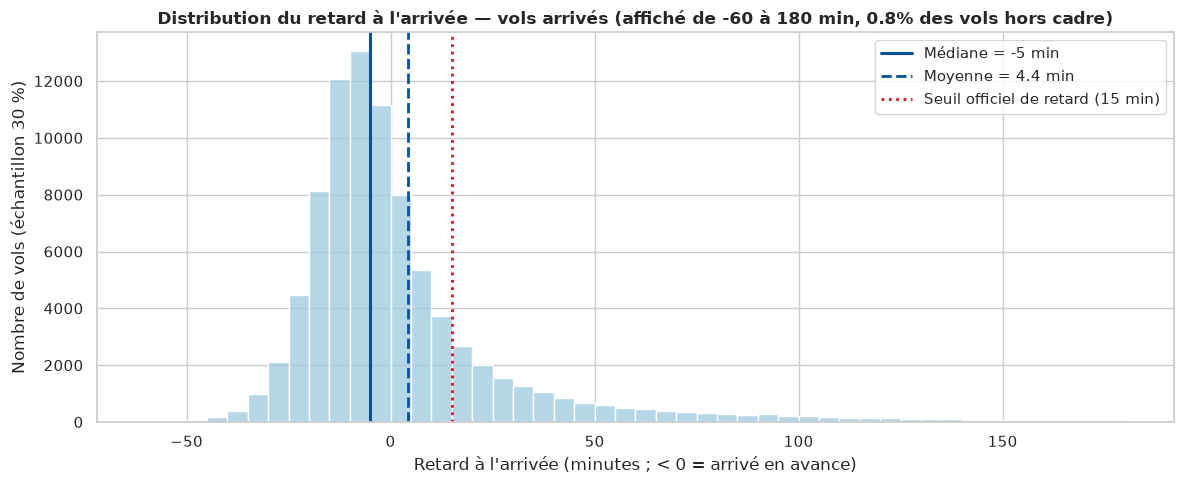

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

warnings.filterwarnings("ignore", message=".*pandas >= 3.0.0.*")
sns.set_theme(style="whitegrid", context="notebook")
SILVER_MAIN_PATH = globals().get("SILVER_MAIN_PATH", "/lakehouse/silver/flights_enriched")

silver_eda = spark.read.format("delta").load(SILVER_MAIN_PATH)

# Périmètre
perimetre = silver_eda.agg(
    F.count("*").alias("n_total"),
    F.sum(F.col("is_cancelled").cast("int")).alias("n_annules"),
    F.sum(F.col("is_diverted").cast("int")).alias("n_derouted"),
    F.sum(F.col("arrival_delay").isNotNull().cast("int")).alias("n_arrival_delay_renseigne"),
).first().asDict()
print("=== Périmètre ===")
for k, v in perimetre.items():
    print(f"  {k:<28} {v:>9,}  ({v / perimetre['n_total']:6.2%})")

# arrival_delay n'existe que pour les vols arrivés
flown_eda = silver_eda.filter(~F.col("is_cancelled") & ~F.col("is_diverted") & F.col("arrival_delay").isNotNull()).cache()

# Forme de la distribution de arrival_delay
probs = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
d = flown_eda.agg(
    F.count("arrival_delay").alias("n"),
    F.mean("arrival_delay").alias("moyenne"),
    F.stddev("arrival_delay").alias("ecart_type"),
    F.skewness("arrival_delay").alias("skewness"),
    F.min("arrival_delay").alias("min"),
    F.max("arrival_delay").alias("max"),
    F.percentile_approx("arrival_delay", probs, 10000).alias("q"),
    F.avg((F.col("arrival_delay") < 0).cast("int")).alias("part_en_avance"),
    F.avg((F.col("arrival_delay") >= 15).cast("int")).alias("taux_retard_15"),
    F.avg((F.col("arrival_delay") >= 60).cast("int")).alias("taux_retard_60"),
).first().asDict()
q = dict(zip(probs, d.pop("q")))

print("\n=== Distribution de arrival_delay (vols arrivés, minutes) ===")
print(f"  n = {d['n']:,} | min = {d['min']} | max = {d['max']}")
print(f"  Moyenne = {d['moyenne']:.2f} | Écart-type = {d['ecart_type']:.2f} | Skewness = {d['skewness']:.2f}")
print("  Quantiles : " + " | ".join(f"P{int(p*100)} = {v}" for p, v in q.items()))
print(f"  Médiane = {q[0.5]} | IQR (P75 - P25) = {q[0.75] - q[0.25]}")
print(f"  Vols en avance (< 0)      : {d['part_en_avance']:.1%}")
print(f"  Vols en retard >= 15 min  : {d['taux_retard_15']:.1%}")
print(f"  Vols en retard >= 60 min  : {d['taux_retard_60']:.1%}")

# Poids de la queue
minutes = flown_eda.filter(F.col("arrival_delay") > 0).agg(
    F.sum("arrival_delay").alias("total"),
    F.sum(F.when(F.col("arrival_delay") >= 60, F.col("arrival_delay"))).alias("ge60"),
    F.count("*").alias("n_pos"),
    F.sum((F.col("arrival_delay") >= 60).cast("int")).alias("n_ge60"),
).first()
print(f"\nRetards >= 60 min : {minutes['n_ge60'] / minutes['n_pos']:.1%} des vols arrivés en retard "
      f"mais {minutes['ge60'] / minutes['total']:.1%} du total des minutes de retard")

# Histogramme
LOW, HIGH = -60, 180
hist_pd = (
    flown_eda.filter(F.col("arrival_delay").between(LOW, HIGH))
    .select("arrival_delay").sample(fraction=0.30, seed=42).toPandas()
)
part_masquee = 1 - flown_eda.filter(F.col("arrival_delay").between(LOW, HIGH)).count() / d["n"]

fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(hist_pd["arrival_delay"], binwidth=5, color="#9ecae1", edgecolor="white", ax=ax)
ax.axvline(q[0.5], color="#08519c", linewidth=2.2, label=f"Médiane = {q[0.5]} min")
ax.axvline(d["moyenne"], color="#08519c", linestyle="--", linewidth=2, label=f"Moyenne = {d['moyenne']:.1f} min")
ax.axvline(15, color="#cb181d", linestyle=":", linewidth=2, label="Seuil officiel de retard (15 min)")
ax.set_title(f"Distribution du retard à l'arrivée — vols arrivés (affiché de {LOW} à {HIGH} min, {part_masquee:.1%} des vols hors cadre)",
             fontweight="bold")
ax.set_xlabel("Retard à l'arrivée (minutes ; < 0 = arrivé en avance)")
ax.set_ylabel("Nombre de vols (échantillon 30 %)")
ax.legend()
plt.tight_layout()
plt.show()


**Interprétation**

1,8 % des vols sont annulés ou déroutés : ils n'ont pas de retard à l'arrivée et sont exclus de cette mesure.

La distribution est très asymétrique (skewness de 6,5). La moyenne est de +4,4 min alors que la médiane est de −5 min : la plupart des vols arrivent en avance (61 %), et quelques très gros retards tirent la moyenne vers le haut. Les retards de plus d'une heure ne font que 16 % des vols en retard mais 58 % des minutes de retard. L'écart-type (39 min) est lui aussi gonflé par rapport à l'IQR (21 min).

La moyenne n'est donc pas un bon indicateur ici. Pour la suite on retient :
- le taux de vols en retard de 15 min ou plus, indicateur principal (simple à lire et peu sensible aux valeurs extrêmes) ;
- la médiane et l'IQR pour comparer les distributions entre groupes.

Sur l'ensemble, 18,7 % des vols arrivent en retard : c'est la référence pour les étapes suivantes.

Avant de chercher quand et où les retards se produisent, on regarde d'où ils viennent (étape 1).

### Étape 1 : d'où vient le retard ?

Avant de chercher les facteurs, on veut savoir à quel moment le retard apparaît et pour quelle raison. Cela nous dira quels facteurs étudier ensuite.

Deux analyses :
- un tableau croisé départ en retard / arrivée en retard (deux variables binaires), complété par le partage des minutes de retard entre le départ et le trajet ;
- la part des minutes de retard par cause. On compte les minutes plutôt que le nombre de vols pour tenir compte de la gravité, et on utilise des barres triées parce qu'il y a seulement 5 catégories à comparer.

Effectifs :
arrivee          arrivé en retard  arrivé à l'heure
depart                                             
parti en retard             41679             10912
parti à l'heure             11691            221449

% par ligne :
arrivee          arrivé en retard  arrivé à l'heure
depart                                             
parti en retard              79.3              20.7
parti à l'heure               5.0              95.0

Parmi les vols arrivés en retard, % partis à l'heure : 21.9

Vols en retard : 93.3% des minutes de retard existent déjà au départ, 6.7% s'ajoutent pendant le trajet (roulage + vol)



Répartition des minutes de retard par cause :
                                             cause  minutes  part_pct
                         Avion précédent en retard  1247727      39.9
   Compagnie (équipage, maintenance, embarquement)  1001649      32.0
Système aérien (trafic, contrôle aérien, aéroport)   715283      22.9
                                     Météo extrême   158910       5.1
                                          Sécurité     4366       0.1


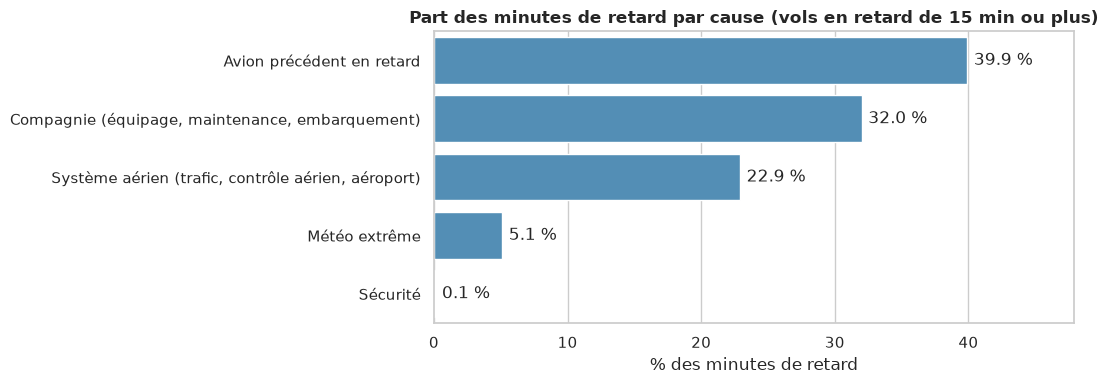

In [ ]:
# Le retard se crée-t-il avant ou après le départ ?
dep_arr_pd = (
    flown_eda.filter(F.col("departure_delay").isNotNull())
    .withColumn("depart", F.when(F.col("departure_delay") >= 15, "parti en retard").otherwise("parti à l'heure"))
    .withColumn("arrivee", F.when(F.col("is_delayed_15"), "arrivé en retard").otherwise("arrivé à l'heure"))
    .groupBy("depart", "arrivee").count()
    .toPandas()
)
ct = pd.crosstab(dep_arr_pd["depart"], dep_arr_pd["arrivee"], values=dep_arr_pd["count"], aggfunc="sum")
print("Effectifs :")
print(ct.to_string())
print("\n% par ligne :")
print((ct.div(ct.sum(axis=1), axis=0) * 100).round(1).to_string())
print("\nParmi les vols arrivés en retard, % partis à l'heure :",
      round(100 * ct.loc["parti à l'heure", "arrivé en retard"] / ct["arrivé en retard"].sum(), 1))

# Pour les vols en retard : minutes perdues au départ vs pendant le trajet
late = flown_eda.filter(F.col("is_delayed_15"))
split = late.agg(
    F.sum("departure_delay").alias("min_depart"),
    F.sum(F.col("arrival_delay") - F.col("departure_delay")).alias("min_trajet"),
).first()
total = split["min_depart"] + split["min_trajet"]
print(f"\nVols en retard : {split['min_depart'] / total:.1%} des minutes de retard existent déjà au départ, "
      f"{split['min_trajet'] / total:.1%} s'ajoutent pendant le trajet (roulage + vol)")

# Causes : part des minutes de retard par cause (colonnes renseignées pour les vols en retard >= 15 min)
cause_labels = {
    "late_aircraft_delay": "Avion précédent en retard",
    "airline_delay": "Compagnie (équipage, maintenance, embarquement)",
    "air_system_delay": "Système aérien (trafic, contrôle aérien, aéroport)",
    "weather_delay": "Météo extrême",
    "security_delay": "Sécurité",
}
causes_pd = (
    late.agg(*[F.sum(c).alias(c) for c in cause_labels]).toPandas().T
    .rename(columns={0: "minutes"})
)
causes_pd["part_pct"] = (100 * causes_pd["minutes"] / causes_pd["minutes"].sum()).round(1)
causes_pd["cause"] = causes_pd.index.map(cause_labels)
causes_pd = causes_pd.sort_values("minutes", ascending=False)
print("\nRépartition des minutes de retard par cause :")
print(causes_pd[["cause", "minutes", "part_pct"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=causes_pd, x="part_pct", y="cause", color="#4292c6", ax=ax)
for i, v in enumerate(causes_pd["part_pct"]):
    ax.text(v + 0.5, i, f"{v:.1f} %", va="center")
ax.set_title("Part des minutes de retard par cause (vols en retard de 15 min ou plus)", fontweight="bold")
ax.set_xlabel("% des minutes de retard")
ax.set_ylabel("")
ax.set_xlim(0, causes_pd["part_pct"].max() + 8)
plt.tight_layout()
plt.show()


**Interprétation**

Le retard se joue surtout avant le décollage : 79 % des vols partis en retard arrivent en retard (5 % pour les autres), et 93 % des minutes de retard existent déjà au départ.

Les causes orientent la suite :
- avion précédent en retard (40 %) : le retard se propage, à vérifier selon l'heure (étape 2) ;
- compagnie (32 %) : comparer les compagnies (étape 3) ;
- système aérien (23 %) : dépend de l'aéroport (étape 4) ;
- météo extrême (5 %) : la météo ordinaire est comptée dans le système aérien, effet saisonnier possible (étape 2).

### Étape 2 : quand les vols sont-ils en retard ?

L'étape 1 a montré que le retard se propage d'un vol à l'autre et que la météo peut jouer. On vérifie ces deux pistes avec le taux de retard par heure de départ prévue, par jour et par mois. Ces trois variables sont ordonnées, d'où des courbes, comparées au taux global de 18,7 %. Pour chaque groupe, on calcule aussi la part des minutes de retard due à l'avion précédent et, par mois, la part des annulations dues à la météo.

Par heure de départ prévue :
 dep_hour  n_vols  taux_retard  part_min_avion_precedent
        0     755         13.9                      27.3
        1     261         24.9                      33.8
        2      60         25.0                      65.8
        3      36         11.1                      91.7
        4      26         26.9                      47.2
        5    5841          7.2                       4.9
        6   19872          9.1                       5.6
        7   19160         11.4                       8.4
        8   18564         13.1                      16.6
        9   17350         14.5                      28.9
       10   18391         15.0                      38.4
       11   17944         16.3                      39.4
       12   17306         17.2                      43.7
       13   17874         18.7                      43.1
       14   16100         20.6                      42.7
       15   18086         21.6                      43.1
  

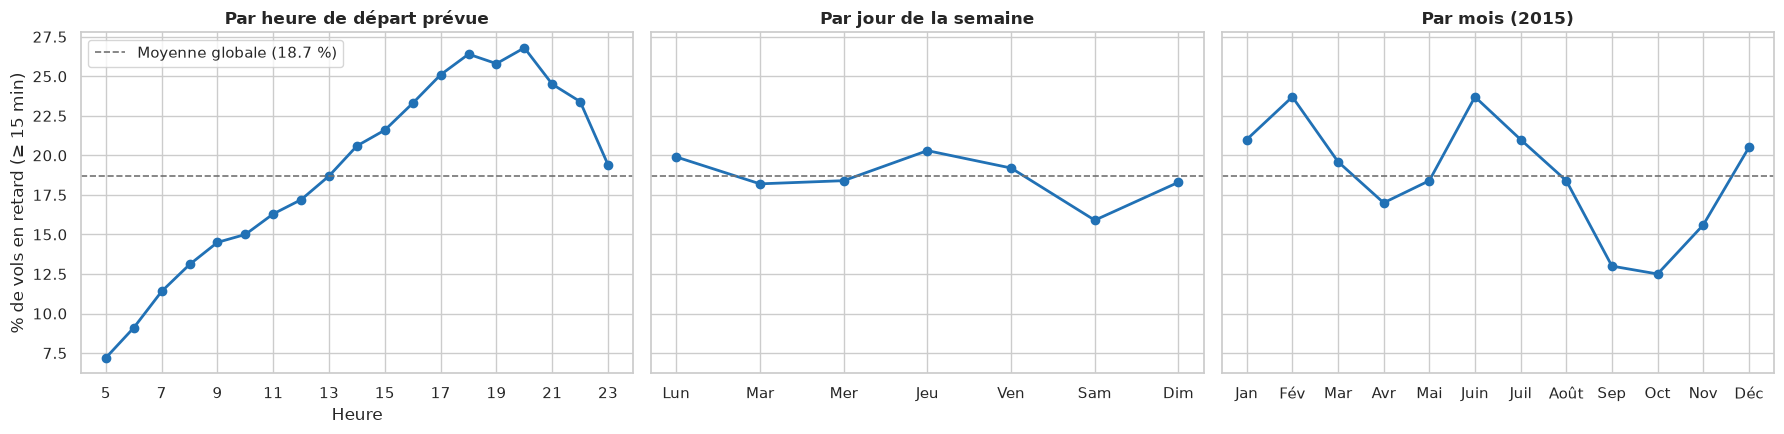

In [ ]:
TAUX_REF = 100 * d["taux_retard_15"]  # taux global calculé à l'étape 0

def taux_par(col):
    return (
        flown_eda.groupBy(col)
        .agg(
            F.count("*").alias("n_vols"),
            F.round(100 * F.avg(F.col("is_delayed_15").cast("int")), 1).alias("taux_retard"),
            F.round(100 * F.sum("late_aircraft_delay") / F.sum(F.when(F.col("is_delayed_15"), F.col("arrival_delay"))), 1)
             .alias("part_min_avion_precedent"),
        )
        .orderBy(col)
        .toPandas()
    )

heure_pd = taux_par("dep_hour")
jour_pd = taux_par("day_of_week")
mois_pd = taux_par("month")

# Annulations par mois, et part des annulations dues à la météo (motif B)
annul_pd = (
    silver_eda.groupBy("month")
    .agg(
        F.round(100 * F.avg(F.col("is_cancelled").cast("int")), 2).alias("taux_annulation"),
        F.round(100 * F.avg((F.col("cancellation_reason") == "B").cast("int")), 2).alias("part_annul_meteo"),
    )
    .orderBy("month").toPandas()
)
mois_pd = mois_pd.merge(annul_pd, on="month")

print("Par heure de départ prévue :")
print(heure_pd.to_string(index=False))
print("\nPar jour (1 = lundi) :")
print(jour_pd.to_string(index=False))
print("\nPar mois :")
print(mois_pd.to_string(index=False))

# Entre minuit et 5 h il y a très peu de vols : on trace de 5 h à 23 h
heure_plot = heure_pd[heure_pd["dep_hour"] >= 5]
jours = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
mois_lbl = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
axes[0].plot(heure_plot["dep_hour"], heure_plot["taux_retard"], marker="o", color="#2171b5", linewidth=2)
axes[0].set_xticks(range(5, 24, 2))
axes[0].set_title("Par heure de départ prévue", fontweight="bold")
axes[0].set_xlabel("Heure")
axes[0].set_ylabel("% de vols en retard (≥ 15 min)")

axes[1].plot(jours, jour_pd["taux_retard"], marker="o", color="#2171b5", linewidth=2)
axes[1].set_title("Par jour de la semaine", fontweight="bold")

axes[2].plot(mois_lbl, mois_pd["taux_retard"], marker="o", color="#2171b5", linewidth=2)
axes[2].set_title("Par mois (2015)", fontweight="bold")

for ax in axes:
    ax.axhline(TAUX_REF, color="#737373", linestyle="--", linewidth=1.2, label=f"Moyenne globale ({TAUX_REF:.1f} %)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()


**Interprétation**

- Heure : le taux de retard passe de 7 % à 5 h à 27 % vers 20 h, et la part due à l'avion précédent de 5 % à 50 %. Cela confirme la propagation au fil de la journée. C'est le facteur temporel le plus fort.
- Mois : pics en février (24 %, 78 % des annulations dues à la météo), en juin et en décembre, creux en septembre-octobre (13 %). La saison joue, en partie via la météo.
- Jour : peu d'écart (16 % le samedi, 18 à 20 % les autres jours). Facteur secondaire.

On retient l'heure et le mois pour la suite (hypothèses à tester en J4, table Gold mensuelle en J3).

### Étape 2 bis : quel est le poids des événements exceptionnels ?

Les pics de février, juin et décembre pourraient venir de quelques journées exceptionnelles (tempêtes, pannes) plutôt que de la saison. On calcule les taux jour par jour et on repère les jours exceptionnels avec la règle de Tukey (au-dessus de Q3 + 1,5 IQR), en retard ou en annulation. On compare ensuite les taux mensuels avec et sans ces jours. Les dates des plus gros pics ont été recoupées avec les rapports de la NOAA et la presse.

Seuils : retard > 38.5 % ou annulation > 3.5 %  ->  40 jours exceptionnels sur 365

Les 8 jours avec le plus d'annulations :
flight_date  n_vols  taux_retard  taux_annulation
 2015-01-27     784          6.3             19.3
 2015-02-02     838         29.7             18.0
 2015-03-05     854         31.9             17.1
 2015-02-01     649         22.1             14.5
 2015-12-28     853         35.8             12.7
 2015-03-01     766         41.5             10.8
 2015-01-26     774         18.8              9.3
 2015-02-23     809         28.1              9.3

Taux mensuels (%) avec et sans les jours exceptionnels :
       jours_exceptionnels  retard_tous  retard_sans  annulation_tous  annulation_sans
month                                                                                 
1                        6        20.99        19.60             2.60             1.35
2                       13        23.66        20.77             4.86             1.61
3                  

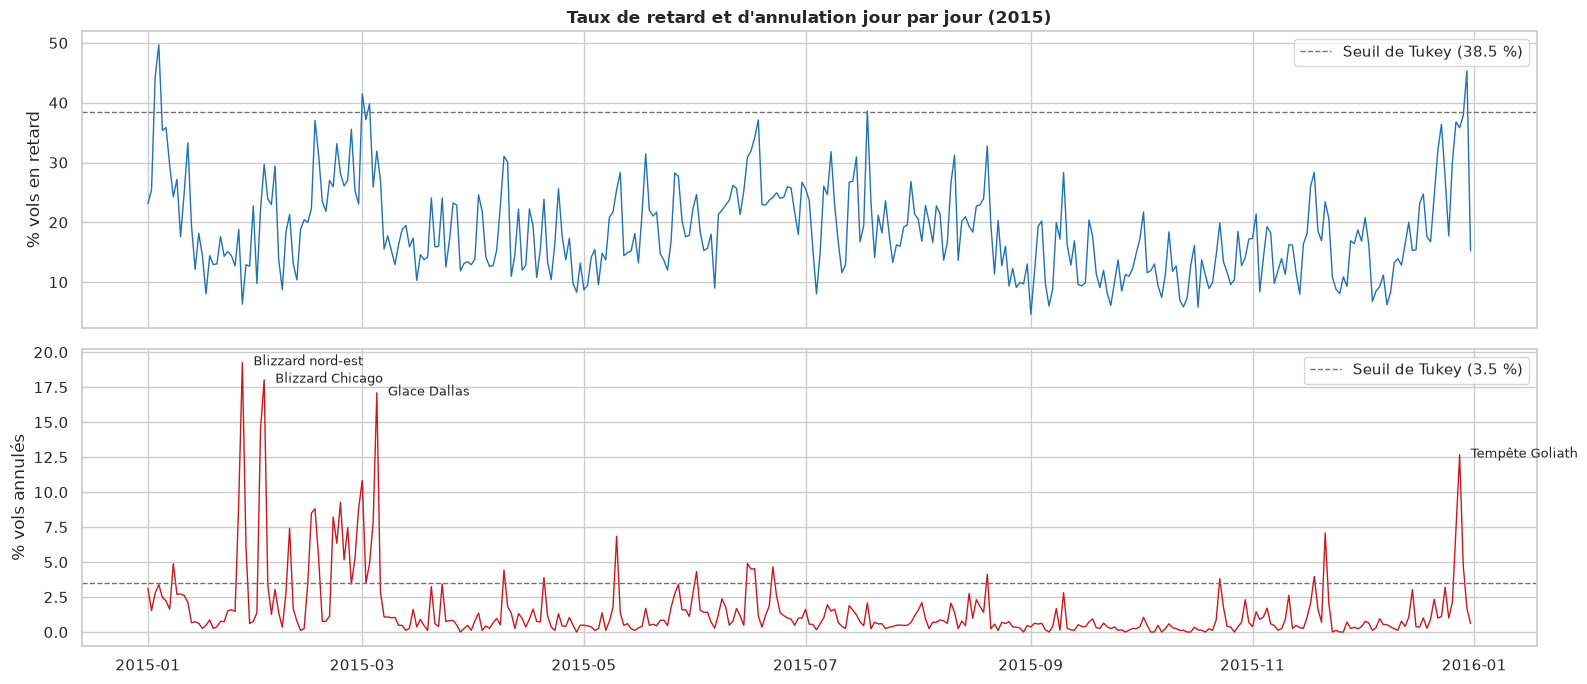

In [ ]:
# Taux de retard et d'annulation pour chaque jour de 2015
jour_pd = (
    silver_eda.groupBy("flight_date")
    .agg(
        F.count("*").alias("n_vols"),
        F.count("is_delayed_15").alias("n_arrives"),  # le retard ne porte que sur les vols arrivés
        (100 * F.avg(F.col("is_delayed_15").cast("int"))).alias("taux_retard"),
        (100 * F.avg(F.col("is_cancelled").cast("int"))).alias("taux_annulation"),
    )
    .orderBy("flight_date").toPandas()
)
jour_pd["flight_date"] = pd.to_datetime(jour_pd["flight_date"])
jour_pd["month"] = jour_pd["flight_date"].dt.month

# Jour exceptionnel = au-dessus du seuil de Tukey (Q3 + 1,5 IQR) en retard ou en annulation
def seuil_tukey(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)

seuil_ret, seuil_ann = seuil_tukey(jour_pd["taux_retard"]), seuil_tukey(jour_pd["taux_annulation"])
jour_pd["exceptionnel"] = (jour_pd["taux_retard"] > seuil_ret) | (jour_pd["taux_annulation"] > seuil_ann)
print(f"Seuils : retard > {seuil_ret:.1f} % ou annulation > {seuil_ann:.1f} %  ->  {jour_pd['exceptionnel'].sum()} jours exceptionnels sur {len(jour_pd)}")
print("\nLes 8 jours avec le plus d'annulations :")
print(jour_pd.nlargest(8, "taux_annulation")[["flight_date", "n_vols", "taux_retard", "taux_annulation"]].round(1).to_string(index=False))

# Taux mensuels avec et sans les jours exceptionnels (moyenne des jours pondérée par le nombre de vols)
def taux_pondere(x, col):
    poids = x["n_arrives"] if col == "taux_retard" else x["n_vols"]
    return round((x[col] * poids).sum() / poids.sum(), 2)

comp = pd.DataFrame({
    "jours_exceptionnels": jour_pd.groupby("month")["exceptionnel"].sum(),
    "retard_tous": jour_pd.groupby("month").apply(taux_pondere, "taux_retard"),
    "retard_sans": jour_pd[~jour_pd["exceptionnel"]].groupby("month").apply(taux_pondere, "taux_retard"),
    "annulation_tous": jour_pd.groupby("month").apply(taux_pondere, "taux_annulation"),
    "annulation_sans": jour_pd[~jour_pd["exceptionnel"]].groupby("month").apply(taux_pondere, "taux_annulation"),
})
print("\nTaux mensuels (%) avec et sans les jours exceptionnels :")
print(comp.to_string())

# Événements identifiés (sources : NOAA, presse locale)
evenements = {
    "2015-01-27": "Blizzard nord-est",
    "2015-02-02": "Blizzard Chicago",
    "2015-03-05": "Glace Dallas",
    "2015-12-28": "Tempête Goliath",
}

fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
axes[0].plot(jour_pd["flight_date"], jour_pd["taux_retard"], color="#2171b5", linewidth=1)
axes[0].axhline(seuil_ret, color="#737373", linestyle="--", linewidth=1, label=f"Seuil de Tukey ({seuil_ret:.1f} %)")
axes[0].set_ylabel("% vols en retard")
axes[0].set_title("Taux de retard et d'annulation jour par jour (2015)", fontweight="bold")
axes[0].legend(loc="upper right")

axes[1].plot(jour_pd["flight_date"], jour_pd["taux_annulation"], color="#cb181d", linewidth=1)
axes[1].axhline(seuil_ann, color="#737373", linestyle="--", linewidth=1, label=f"Seuil de Tukey ({seuil_ann:.1f} %)")
for date, label in evenements.items():
    y = jour_pd.loc[jour_pd["flight_date"] == date, "taux_annulation"].iloc[0]
    axes[1].annotate(label, (pd.Timestamp(date), y), xytext=(8, -2), textcoords="offset points", fontsize=9)
axes[1].set_ylabel("% vols annulés")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()


**Interprétation**

- 40 jours sur 365 sont exceptionnels. Les plus gros pics d'annulations correspondent à des tempêtes : blizzard du nord-est le 27 janvier (19 % d'annulations, New York), blizzard de Chicago le 1er-2 février, tempêtes de glace à Dallas fin février et le 5 mars, tempête Goliath les 27-28 décembre (Chicago et Dallas). Les pics de retard sans annulation correspondent aux retours de vacances (3-4 janvier, 29-30 décembre).
- Les annulations viennent presque entièrement de ces événements : sans eux, février passe de 4,9 % à 1,6 %.
- Les retards gardent leur saisonnalité : sans ces jours, février (20,8 %) et juin (22,6 %) restent au-dessus de la moyenne, septembre reste à 13 %.

Le mois reste donc un facteur de retard, même sans les tempêtes. Ces événements ne sont pas prévisibles à la réservation ; on les garde dans les données, mais ils expliquent la plupart des annulations.

### Étape 3 : les compagnies se valent-elles ?

32 % des minutes de retard sont imputées aux compagnies elles-mêmes (étape 1). On compare donc les 14 compagnies sur le taux de retard (barres triées), avec la médiane et l'IQR en complément. Comme l'heure joue beaucoup (étape 2), on vérifie que les écarts ne viennent pas seulement des horaires : part des vols après 14 h, et taux de retard avant et après 14 h.

airline                 airline_name  n_vols  taux_retard  mediane  iqr  taux_annulation  part_min_compagnie  part_vols_apres_14h
     HA       Hawaiian Airlines Inc.    3785         12.5       -2   12             0.18                57.0                 43.9
     AS         Alaska Airlines Inc.    8685         13.5       -6   18             0.41                31.1                 45.9
     DL         Delta Air Lines Inc.   43601         13.6       -8   18             0.46                38.0                 46.0
     AA       American Airlines Inc.   36544         18.0       -6   22             1.54                34.3                 45.2
     OO        Skywest Airlines Inc.   29391         18.7       -4   20             1.63                32.1                 46.0
     VX               Virgin America    3154         19.1       -4   21             0.92                15.0                 48.2
     WN       Southwest Airlines Co.   63139         19.2       -4   20             1.23  


Taux de retard par créneau :
         avant 14h  après 14h
airline                      
HA            10.7       14.7
AS            11.2       16.2
DL            10.0       17.9
AA            14.2       22.7
OO            16.3       21.5
VX            15.6       23.0
WN            11.6       27.8
EV            15.7       23.8
US            14.9       24.8
UA            16.6       26.2
MQ            19.3       25.2
B6            14.9       30.2
F9            20.8       29.6
NK            25.4       34.7


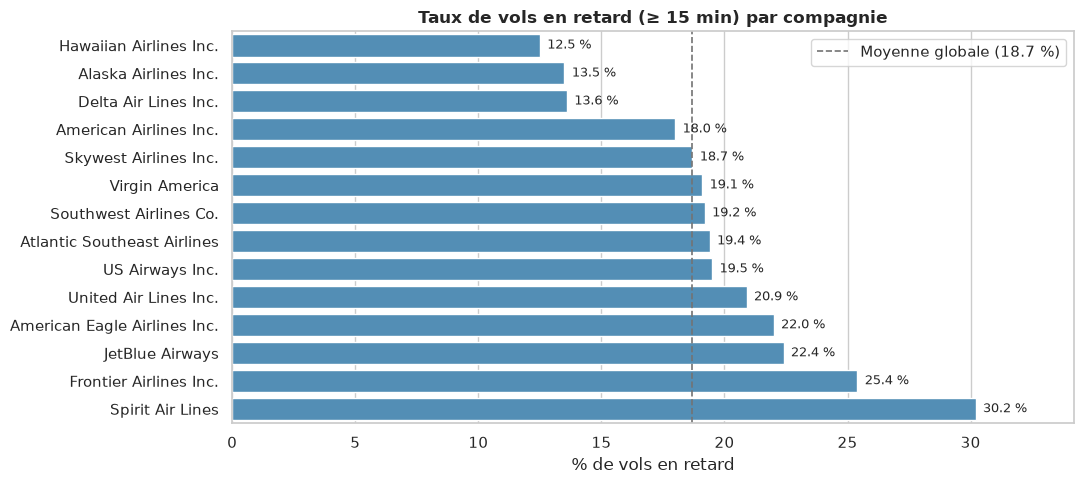

In [ ]:
cie_pd = (
    silver_eda.groupBy("airline", "airline_name")
    .agg(
        F.count("*").alias("n_vols"),
        F.round(100 * F.avg(F.col("is_delayed_15").cast("int")), 1).alias("taux_retard"),
        F.percentile_approx("arrival_delay", 0.5).alias("mediane"),
        (F.percentile_approx("arrival_delay", 0.75) - F.percentile_approx("arrival_delay", 0.25)).alias("iqr"),
        F.round(100 * F.avg(F.col("is_cancelled").cast("int")), 2).alias("taux_annulation"),
        # part des minutes de retard imputées à la compagnie elle-même
        F.round(100 * F.sum("airline_delay") / F.sum(F.when(F.col("is_delayed_15"), F.col("arrival_delay"))), 1).alias("part_min_compagnie"),
        # part des vols programmés l'après-midi / le soir (heures où le retard est plus fréquent)
        F.round(100 * F.avg((F.col("dep_hour") >= 14).cast("int")), 1).alias("part_vols_apres_14h"),
    )
    .orderBy("taux_retard")
    .toPandas()
)
print(cie_pd.to_string(index=False))

# Est-ce la compagnie ou ses horaires ? On compare les compagnies à heure égale (matin vs après-midi)
cie_creneau_pd = (
    flown_eda
    .withColumn("creneau", F.when(F.col("dep_hour") < 14, "avant 14h").otherwise("après 14h"))
    .groupBy("airline").pivot("creneau", ["avant 14h", "après 14h"])
    .agg(F.round(100 * F.avg(F.col("is_delayed_15").cast("int")), 1))
    .toPandas().set_index("airline").loc[cie_pd["airline"]]
)
print("\nTaux de retard par créneau :")
print(cie_creneau_pd.to_string())

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=cie_pd, x="taux_retard", y="airline_name", color="#4292c6", ax=ax)
ax.axvline(TAUX_REF, color="#737373", linestyle="--", linewidth=1.2, label=f"Moyenne globale ({TAUX_REF:.1f} %)")
for i, v in enumerate(cie_pd["taux_retard"]):
    ax.text(v + 0.3, i, f"{v:.1f} %", va="center", fontsize=9)
ax.set_title("Taux de vols en retard (≥ 15 min) par compagnie", fontweight="bold")
ax.set_xlabel("% de vols en retard")
ax.set_ylabel("")
ax.set_xlim(0, cie_pd["taux_retard"].max() + 4)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


**Interprétation**

- L'écart est important : de 12,5 % (Hawaiian) à 30,2 % (Spirit). Delta et Alaska sont aussi sous les 14 %, Frontier et JetBlue au-dessus de 22 %.
- Ce n'est pas une question d'horaires : toutes les compagnies ont 44 à 52 % de vols après 14 h, et le classement reste le même à créneau égal (le matin, 10 % pour Delta contre 25 % pour Spirit).
- La compagnie est donc un facteur à part entière. American Eagle se distingue par ses annulations (5,5 %).

On retient la compagnie pour la suite (test de Kruskal-Wallis en J4, classement en table Gold en J3).

### Étape 4 : les aéroports ont-ils des profils différents ?

23 % des minutes de retard viennent du système aérien (trafic, contrôle, capacité), donc en partie de l'aéroport (étape 1). On calcule pour chaque aéroport de départ le taux de retard, le taux d'annulation, le temps de roulage médian (signe de congestion) et la part due au système aérien. On garde les aéroports avec au moins 300 vols pour avoir des taux fiables, et octobre est exclu (codes non valides). Nos données ont les coordonnées GPS : une carte montre directement si la géographie joue. Le lien entre indicateurs est mesuré avec Spearman, plus robuste sur 104 points.

104 aéroports avec au moins 300 vols dans l'échantillon (92% des vols)

Les 8 moins touchés :
origin_airport    origin_city  n_vols  taux_retard  taux_annulation  taxi_out_median  part_min_systeme
           LIH          Lihue     541          9.5             0.18                7               5.7
           ANC      Anchorage     806         11.9             0.37               12              12.3
           PDX       Portland    2360         12.3             0.42               11              23.1
           HNL       Honolulu    2190         12.6             0.14               15               7.2
           KOA    Kailua/Kona     532         12.6             0.75                9               9.4
           SLC Salt Lake City    4954         13.2             0.34               16              25.0
           ALB         Albany     379         13.6             1.06               11              29.4
           OGG        Kahului    1016         13.8             0.39               

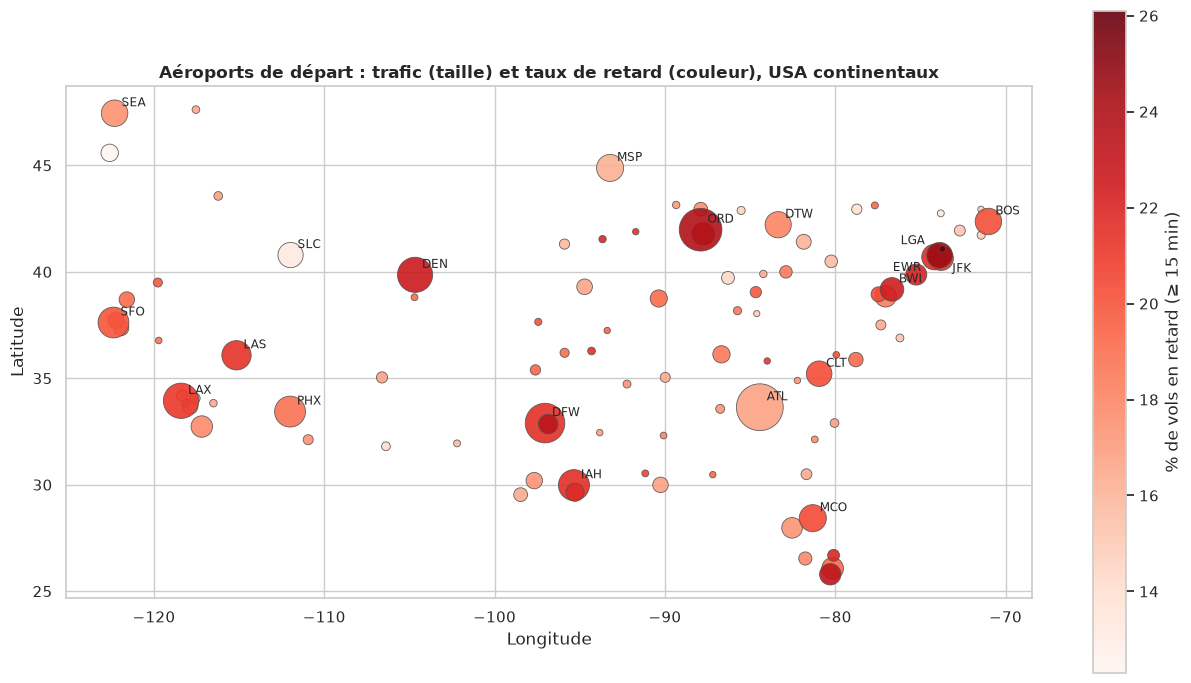

In [ ]:
# Profil des aéroports de départ (octobre exclu : codes aéroport non valides)
apt_pd = (
    silver_eda.filter(F.col("airport_code_valid"))
    .groupBy("origin_airport", "origin_city", "origin_state", "origin_lat", "origin_lon")
    .agg(
        F.count("*").alias("n_vols"),
        F.round(100 * F.avg(F.col("is_delayed_15").cast("int")), 1).alias("taux_retard"),
        F.round(100 * F.avg(F.col("is_cancelled").cast("int")), 2).alias("taux_annulation"),
        F.percentile_approx("taxi_out", 0.5).alias("taxi_out_median"),
        F.round(100 * F.sum("air_system_delay") / F.sum(F.when(F.col("is_delayed_15"), F.col("arrival_delay"))), 1).alias("part_min_systeme"),
    )
    .toPandas()
)
# On garde les aéroports avec assez de vols pour que le taux soit fiable
apt_pd = apt_pd[apt_pd["n_vols"] >= 300].sort_values("taux_retard")
print(f"{len(apt_pd)} aéroports avec au moins 300 vols dans l'échantillon "
      f"({apt_pd['n_vols'].sum() / silver_eda.filter('airport_code_valid').count():.0%} des vols)")
cols = ["origin_airport", "origin_city", "n_vols", "taux_retard", "taux_annulation", "taxi_out_median", "part_min_systeme"]
print("\nLes 8 moins touchés :")
print(apt_pd[cols].head(8).to_string(index=False))
print("\nLes 8 plus touchés :")
print(apt_pd[cols].tail(8).to_string(index=False))

# Le roulage au départ (signe de congestion) va-t-il avec le retard ?
print("\nCorrélation de Spearman entre aéroports :")
print(apt_pd[["taux_retard", "taxi_out_median", "taux_annulation", "part_min_systeme", "n_vols"]]
      .corr(method="spearman")["taux_retard"].round(2).to_string())

# Carte : position = coordonnées GPS, taille = trafic, couleur = taux de retard
carte = apt_pd[(apt_pd["origin_lon"] > -130) & (apt_pd["origin_lat"] > 23)]  # USA continentaux
fig, ax = plt.subplots(figsize=(13, 7))
sc = ax.scatter(carte["origin_lon"], carte["origin_lat"], s=carte["n_vols"] / 15, c=carte["taux_retard"],
                cmap="Reds", edgecolors="#525252", linewidth=0.6, alpha=0.9)
decalages = {"LGA": (-28, 8), "JFK": (8, -10), "EWR": (-30, -10)}  # aéroports de New York, très proches
for _, r in carte[carte["n_vols"] >= 4000].iterrows():
    ax.annotate(r["origin_airport"], (r["origin_lon"], r["origin_lat"]), xytext=decalages.get(r["origin_airport"], (5, 5)),
                textcoords="offset points", fontsize=8.5)
plt.colorbar(sc, ax=ax, label="% de vols en retard (≥ 15 min)")
ax.set_title("Aéroports de départ : trafic (taille) et taux de retard (couleur), USA continentaux", fontweight="bold")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1.25)
plt.tight_layout()
plt.show()


**Interprétation**

- Les aéroports varient de 9,5 % (Lihue) à 26 % (White Plains). Les moins touchés sont à Hawaï, en Alaska et dans le nord-ouest (Portland, Salt Lake City). Les plus touchés sont dans le nord-est (New York, Philadelphie), à Chicago, Denver, Dallas et en Floride du Sud.
- Le roulage (ρ = 0,38) et les annulations (ρ = 0,30) vont avec le retard : la congestion joue. La taille compte peu (ρ = 0,27). Atlanta, le plus gros aéroport, reste sous la moyenne (17 %).
- Les aéroports combinent ces indicateurs de façon différente (LGA : congestion et annulations ; DAL : roulage court mais beaucoup de retards). Une segmentation K-Means des aéroports en J4 a donc du sens, avec ces indicateurs comme variables.

### Étape 5 : vue d'ensemble des aéroports par ACP

L'étape 4 a montré que les aéroports combinent plusieurs indicateurs de façon différente. Pour les regarder tous en même temps, on fait une Analyse en Composantes Principales (ACP) sur les aéroports de départ (au moins 300 vols, octobre exclu).

Variables, toutes calculées par aéroport :
- résultat : taux de retard (≥ 15 min), taux d'annulation ;
- congestion : roulage au départ médian, trafic (en log, car très asymétrique) ;
- type de desserte : distance médiane, part des départs après 17 h ;
- origine des minutes de retard : part due au système aérien, à la météo, à un avion arrivé en retard.

Les variables n'ont pas les mêmes unités, on les centre-réduit (`StandardScaler`) avant l'ACP. On lit le cercle des corrélations (ce que représente chaque axe) et la projection des aéroports. Ces mêmes variables serviront au K-Means en J4.


104 aéroports, 9 variables centrées-réduites
Variance expliquée : CP1 = 28.7% | CP2 = 24.2% | CP3 = 12.9% | CP4 = 11.1% | CP5 = 7.5%
Cumul CP1 + CP2 = 52.8% | CP1 à CP3 = 65.8%

Corrélation de chaque variable avec les 3 premiers axes :
                     CP1   CP2   CP3
taux_retard         0.65 -0.29  0.19
taux_annulation     0.11 -0.65  0.34
roulage_median      0.82 -0.20 -0.09
log_trafic          0.78  0.48  0.08
distance_mediane    0.65  0.18 -0.26
part_depart_soir    0.52  0.65  0.11
part_systeme        0.15 -0.60 -0.62
part_meteo          0.18 -0.41  0.72
part_avion_retarde -0.38  0.65  0.18


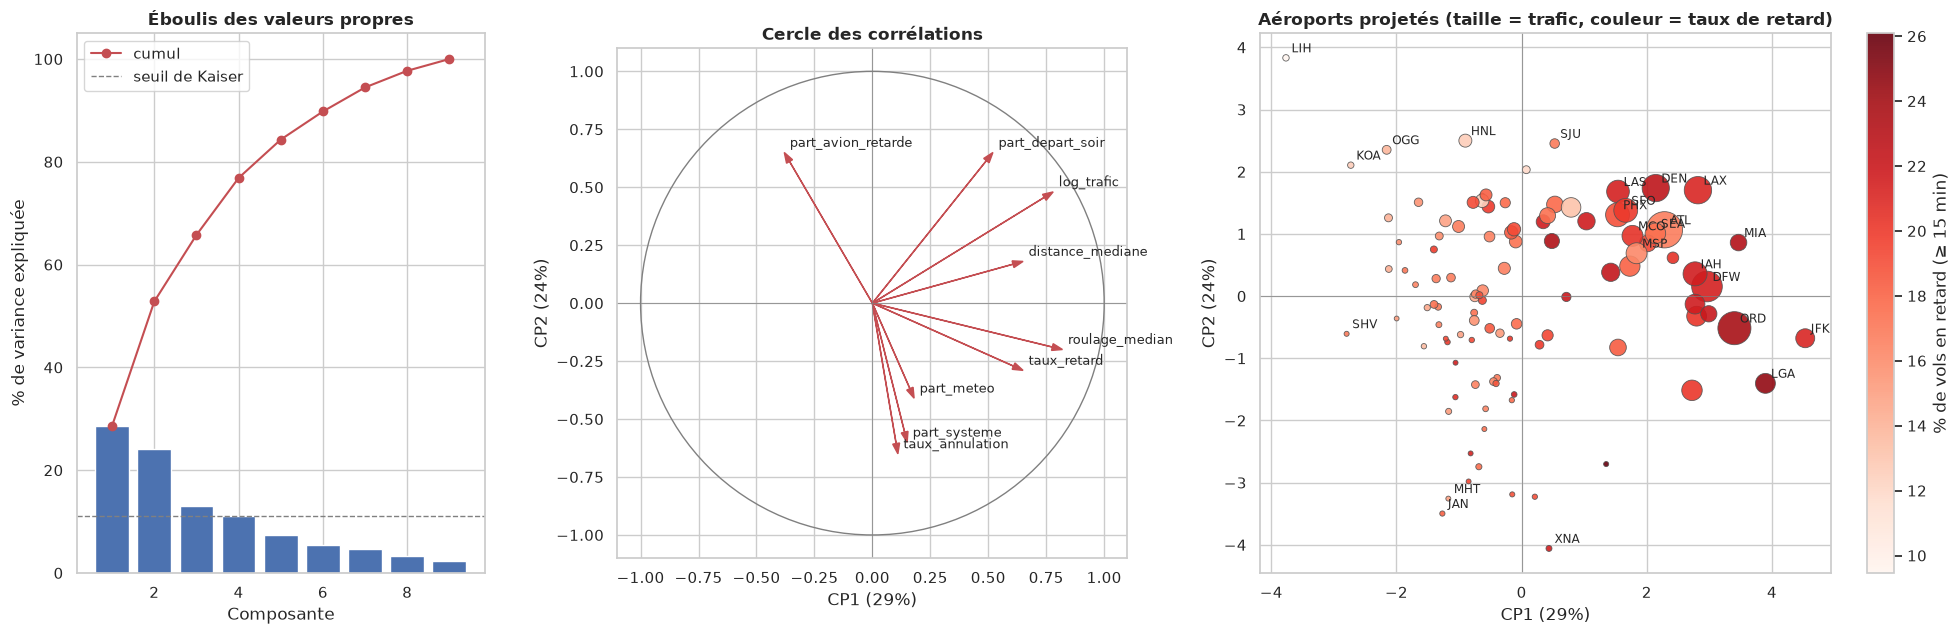


CP1 - les 5 plus négatifs :
origin_airport origin_city  n_vols  taux_retard  roulage_median  distance_mediane  part_meteo   CP1
           LIH       Lihue     541         9.46               7               102        5.58 -3.77
           SHV  Shreveport     331        16.92              10               192        3.37 -2.80
           KOA Kailua/Kona     532        12.57               9               163        4.26 -2.73
           OGG     Kahului    1016        13.85               9               201        2.72 -2.16
           BUF     Buffalo     828        14.02              11               468        0.25 -2.13
CP1 - les 5 plus positifs :
origin_airport  origin_city  n_vols  taux_retard  roulage_median  distance_mediane  part_meteo  CP1
           JFK     New York    4656        21.14              23              1089        7.62 4.53
           LGA     New York    5135        24.60              23               762        2.98 3.90
           MIA        Miami    3551        

In [18]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Une ligne par aéroport de départ (agrégation côté Spark, ~300 lignes ramenées en pandas)
causes = ["air_system_delay", "weather_delay", "late_aircraft_delay", "airline_delay", "security_delay"]
total_causes = sum(F.coalesce(F.sum(c), F.lit(0)) for c in causes)
apt_acp = (
    silver_eda.filter(F.col("airport_code_valid"))
    .groupBy("origin_airport", "origin_city")
    .agg(
        F.count("*").alias("n_vols"),
        (100 * F.avg(F.col("is_delayed_15").cast("int"))).alias("taux_retard"),
        (100 * F.avg(F.col("is_cancelled").cast("int"))).alias("taux_annulation"),
        F.percentile_approx("taxi_out", 0.5).alias("roulage_median"),
        F.percentile_approx("distance", 0.5).alias("distance_mediane"),
        (100 * F.avg((F.col("dep_hour") >= 17).cast("int"))).alias("part_depart_soir"),
        (100 * F.sum("air_system_delay") / total_causes).alias("part_systeme"),
        (100 * F.sum("weather_delay") / total_causes).alias("part_meteo"),
        (100 * F.sum("late_aircraft_delay") / total_causes).alias("part_avion_retarde"),
    )
    .filter(F.col("n_vols") >= 300)
    .toPandas()
    .dropna()
)
apt_acp["log_trafic"] = np.log10(apt_acp["n_vols"])

features = ["taux_retard", "taux_annulation", "roulage_median", "log_trafic", "distance_mediane",
            "part_depart_soir", "part_systeme", "part_meteo", "part_avion_retarde"]
X = StandardScaler().fit_transform(apt_acp[features])

# 2. ACP sur toutes les composantes pour lire la variance expliquée
acp = PCA().fit(X)
var = acp.explained_variance_ratio_
coords = acp.transform(X)
apt_acp["CP1"], apt_acp["CP2"] = coords[:, 0], coords[:, 1]
print(f"{len(apt_acp)} aéroports, {len(features)} variables centrées-réduites")
print("Variance expliquée : " + " | ".join(f"CP{i+1} = {v:.1%}" for i, v in enumerate(var[:5])))
print(f"Cumul CP1 + CP2 = {var[:2].sum():.1%} | CP1 à CP3 = {var[:3].sum():.1%}")

# Corrélation variable / composante (= coordonnées sur le cercle des corrélations)
correl = pd.DataFrame(acp.components_[:3].T * np.sqrt(acp.explained_variance_[:3]),
                      index=features, columns=["CP1", "CP2", "CP3"]).round(2)
print("\nCorrélation de chaque variable avec les 3 premiers axes :")
print(correl.to_string())

# 3. Graphiques : éboulis, cercle des corrélations, projection des aéroports
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5), gridspec_kw={"width_ratios": [0.8, 1, 1.4]})

ax = axes[0]
ax.bar(range(1, len(var) + 1), 100 * var, color="#4C72B0")
ax.plot(range(1, len(var) + 1), 100 * np.cumsum(var), "o-", color="#C44E52", label="cumul")
ax.axhline(100 / len(features), ls="--", color="grey", lw=1, label="seuil de Kaiser")
ax.set_xlabel("Composante")
ax.set_ylabel("% de variance expliquée")
ax.set_title("Éboulis des valeurs propres", fontweight="bold")
ax.legend()

ax = axes[1]
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for f, (x, y) in correl[["CP1", "CP2"]].iterrows():
    ax.arrow(0, 0, x, y, head_width=0.03, color="#C44E52", length_includes_head=True)
    ax.annotate(f, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal",
       xlabel=f"CP1 ({var[0]:.0%})", ylabel=f"CP2 ({var[1]:.0%})")
ax.set_title("Cercle des corrélations", fontweight="bold")

ax = axes[2]
sc = ax.scatter(apt_acp["CP1"], apt_acp["CP2"], c=apt_acp["taux_retard"], s=apt_acp["n_vols"] / 25,
                cmap="Reds", edgecolors="#525252", linewidth=0.6, alpha=0.9)
a_nommer = pd.concat([apt_acp.nlargest(12, "n_vols"), apt_acp.nlargest(4, "CP1"), apt_acp.nsmallest(4, "CP1"),
                      apt_acp.nlargest(3, "CP2"), apt_acp.nsmallest(3, "CP2")]).drop_duplicates("origin_airport")
for _, r in a_nommer.iterrows():
    ax.annotate(r["origin_airport"], (r["CP1"], r["CP2"]), xytext=(4, 4), textcoords="offset points", fontsize=8.5)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
plt.colorbar(sc, ax=ax, label="% de vols en retard (≥ 15 min)")
ax.set(xlabel=f"CP1 ({var[0]:.0%})", ylabel=f"CP2 ({var[1]:.0%})")
ax.set_title("Aéroports projetés (taille = trafic, couleur = taux de retard)", fontweight="bold")
plt.tight_layout()
plt.show()

# Aéroports extrêmes sur chaque axe, pour nommer les axes
cols = ["origin_airport", "origin_city", "n_vols", "taux_retard", "roulage_median", "distance_mediane", "part_meteo"]
for axe in ["CP1", "CP2"]:
    print(f"\n{axe} - les 5 plus négatifs :")
    print(apt_acp.nsmallest(5, axe)[cols + [axe]].round(2).to_string(index=False))
    print(f"{axe} - les 5 plus positifs :")
    print(apt_acp.nlargest(5, axe)[cols + [axe]].round(2).to_string(index=False))


**Interprétation**

- Pas de facteur unique : les deux premiers axes résument 53 % de l'information (29 % + 24 %) et 4 axes passent le seuil de Kaiser (11 %). On lit les deux premiers.
- **CP1 = taille et congestion.** Il est porté par le roulage (0,82), le trafic (0,78), la distance (0,65) et le taux de retard (0,65). À droite, les grands hubs (JFK, LGA, ORD, MIA, PHL) ; à gauche, les petits aéroports peu congestionnés (Hawaï, Shreveport, Buffalo). Le retard augmente avec la congestion, comme à l'étape 4.
- **CP2 = deux façons d'être en retard.** En haut, le retard propagé (avion arrivé en retard, 0,65) et les départs du soir (0,65) : grands réseaux à rotations serrées (LAS, DEN, LAX) et Hawaï. En bas, les annulations (−0,65), le système aérien (−0,60) et la météo (−0,41) : petits aéroports régionaux perturbés par des événements ponctuels (XNA, JAN, MHT, COS, FAT).
- Le taux de retard ne dépend donc pas d'un seul axe : ORD et LGA (hubs congestionnés qui annulent beaucoup) et XNA (21,5 % de retard sans congestion) sont en retard pour des raisons différentes. Classer les aéroports par taux de retard ne suffit pas, d'où la segmentation K-Means en J4 sur ces 9 variables. CP3 (13 %) oppose la météo (0,72) au système aérien (−0,62) : un groupe « aéroports exposés à la météo » pourrait en sortir.


### Conclusion de l'EDA

Indicateur retenu : le taux de vols en retard de 15 min ou plus (18,7 % en moyenne), avec la médiane et l'IQR en complément.

Facteurs connus à la réservation, du plus fort au plus faible :
1. l'heure de départ : de 7 % à 5 h à 27 % vers 20 h, à cause de la propagation des retards entre vols ;
2. la compagnie : de 12,5 % à 30 %, même à heure égale ;
3. le mois : de 12,5 % en octobre à 24 % en février et en juin, et l'écart reste quand on retire les jours de tempête (les annulations, elles, viennent surtout de ces événements) ;
4. l'aéroport de départ : de 9,5 % à 26 %, lié à la congestion ;
5. le jour de la semaine : effet faible.

Suite du projet :
- J3, tables Gold : classement des compagnies, évolution mensuelle, profil des aéroports.
- J4, tests : Kruskal-Wallis sur le retard entre compagnies, χ² entre créneau horaire et retard.
- J4, segmentation : K-Means sur les aéroports avec les 9 variables de l'ACP (étape 5), qui montre au moins deux profils de retard : hubs congestionnés et petits aéroports perturbés par des événements ponctuels.
- Dashboard : un voyageur choisit compagnie, aéroport, mois et créneau, et voit le risque de retard.